# Where Should the Human Labels Go? Simulating Targeted Audits of LLM Relevance Judges

**Research context:** Reducing LLM-judge error in comparisons of retrieval systems <br>
**Study type:** Independent pre-doctoral simulation study <br>
**Data:** Synthetic relevance labels from two seeded simulations; no external data <br>

When a large language model labels the documents that two search systems return, its mistakes only matter for the comparison if they differ between the systems. This notebook simulates that situation with known ground truth. The first simulation shows what a small system-dependent error does to a paired significance test as the number of topics grows. The second compares ways of spending a fixed budget of human labels to correct the comparison. Every number below describes a synthetic world; the companion study on TREC Deep Learning 2023 measures real judges.

## 1. Setup

In [1]:
import os
import platform
import time
import warnings
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.precision", 3)

CACHE = Path(os.environ.get("CACHE_DIR", Path.home() / ".cache" / "targeted_human_audits"))
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

ALPHA = 0.05            # level of every significance test
K = 10                  # evaluation depth: precision at 10
N_PAIRS = 1000          # simulated pairs of systems per condition
SEED_1 = 20260917       # simulation 1: judge error and paired tests
SEED_2 = 20261029       # simulation 2: paired audits

print(f"Python {platform.python_version()} | NumPy {np.__version__} | pandas {pd.__version__} | SciPy {scipy.__version__} | "
      f"matplotlib {mpl.__version__}")

Python 3.12.16 | NumPy 2.5.3 | pandas 3.1.0 | SciPy 1.18.1 | matplotlib 3.11.2


In [2]:
# Figure style shared by every figure in the repository
FONT_URL = "https://raw.githubusercontent.com/octaviopardo/EBGaramond12/master/fonts/ttf/"
FONT_FILES = ("EBGaramond-Regular.ttf", "EBGaramond-Italic.ttf", "EBGaramond-Medium.ttf",
              "EBGaramond-SemiBold.ttf", "EBGaramond-Bold.ttf")

# Categorical colours checked for colour-vision deficiency on every pair (OKLab, Machado et al. 2009).
INK, INK_2, INK_3 = "#000000", "#000000", "#000000"
RULE, GRID, PAPER = "#000000", "#ECEEF1", "#FFFFFF"
NAVY, CRIMSON, TEAL, OCHRE, SLATE = "#2B5A9B", "#C0463E", "#139A84", "#D9962A", "#000000"
NAVY_PALE, CRIMSON_PALE = "#DCE6F3", "#F5DEDC"
# Judge error grows from pale to dark crimson; the same hue marks judge-only evaluation in every figure.
ERROR_RAMP = {0.0: "#E3A9A3", 0.03: CRIMSON, 0.06: "#7A2621"}
NEUTRAL = "#D3D7DD"


def use_eb_garamond(cache_dir: Path) -> str:
    """Register EB Garamond (SIL Open Font Licence), downloading it once if needed."""
    cache_dir.mkdir(parents=True, exist_ok=True)
    for name in FONT_FILES:
        path = cache_dir / name
        if not path.exists():
            try:
                urlretrieve(FONT_URL + name, path)
            except OSError:
                continue
        font_manager.fontManager.addfont(str(path))
    family = "EB Garamond" if "EB Garamond" in {f.name for f in font_manager.fontManager.ttflist} else "serif"
    mpl.rcParams.update({
        "font.family": family, "font.size": 12.5,
        "mathtext.fontset": "custom", "mathtext.rm": family, "mathtext.it": f"{family}:italic",
        "mathtext.bf": f"{family}:semibold", "mathtext.cal": family, "mathtext.sf": family,
        "axes.labelsize": 13.5, "axes.labelcolor": INK_2, "axes.edgecolor": RULE, "axes.linewidth": 0.9,
        "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
        "grid.color": GRID, "grid.linewidth": 0.9,
        "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 12, "ytick.labelsize": 12,
        "xtick.major.width": 0.9, "ytick.major.width": 0.9,
        "legend.frameon": False, "legend.fontsize": 12,
        "figure.facecolor": PAPER, "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": PAPER,
    })
    return family


def new_figure(height: float = 6.0, width: float = 10.0):
    """One figure, one axis; a fixed width keeps every figure at the same scale in the README."""
    fig = plt.figure(figsize=(width, height))
    return fig, fig.add_axes([0.1, 0.15, 0.86, 0.65])


def frame(fig, ax, title, subtitle, note, left=0.1, right=0.96, top_pad=1.25, bottom_pad=1.15):
    """Fix the margins in inches, then write the title block and the source note."""
    w, h = fig.get_size_inches()
    ax.set_position([left, bottom_pad / h, right - left, 1 - (top_pad + bottom_pad) / h])
    fig.text(0.035, 1 - 0.42 / h, title, ha="left", va="baseline", fontsize=18.5, fontweight="semibold", color=INK)
    fig.text(0.035, 1 - 0.74 / h, subtitle, ha="left", va="baseline", fontsize=13.5, color=INK_2, style="italic")
    if note:
        fig.text(0.035, 0.2 / h, note, ha="left", va="baseline", fontsize=10.5, color=INK_3)


def save(fig, name: str):
    fig.savefig(FIG_DIR / name, dpi=300)
    plt.show()


def series_handle(colour, label, lw=2.0, ls="-", marker="o"):
    return Line2D([], [], marker=marker, ls=ls, lw=lw, color=colour, markeredgecolor=PAPER, markersize=8, label=label)


def percent_axis(ax, axis="y", step=20, top=100):
    ticks = np.arange(0, top + 1e-9, step)
    if axis == "y":
        ax.set_yticks(ticks / 100, [f"{t:.0f}%" for t in ticks])
    else:
        ax.set_xticks(ticks / 100, [f"{t:.0f}%" for t in ticks])


FAMILY = use_eb_garamond(CACHE / "fonts")
print("Figure font:", FAMILY)

Figure font: EB Garamond


## 2. How judge error enters a comparison

A system returns ten documents for each topic, and a document is relevant or not. A judge labels each document with some sensitivity on relevant documents and some false-positive rate on the others. Two kinds of error are simulated.

- **Shared error.** Sensitivity and false-positive rate vary from topic to topic, but every system meets the same judge on a given topic. In a paired comparison this error is the same for both systems and cancels.
- **System-dependent error.** Each system's false-positive rate is shifted by its own amount $\delta_s$, drawn with standard deviation $\sigma$. This is what happens if a judge prefers the style of documents that one system retrieves. It does not cancel, and more topics do not average it away.

The difference in precision at 10 between systems A and B is a weighted sum of item labels, $D_{AB} = \sum_i c_i\, y_i$, where $c_i$ is the weight of item $i$ in A's list minus its weight in B's. A document that both systems return has $c_i = 0$ and cannot change the comparison, whatever label it gets. The second simulation uses this to decide where human labels go (Figure 1).

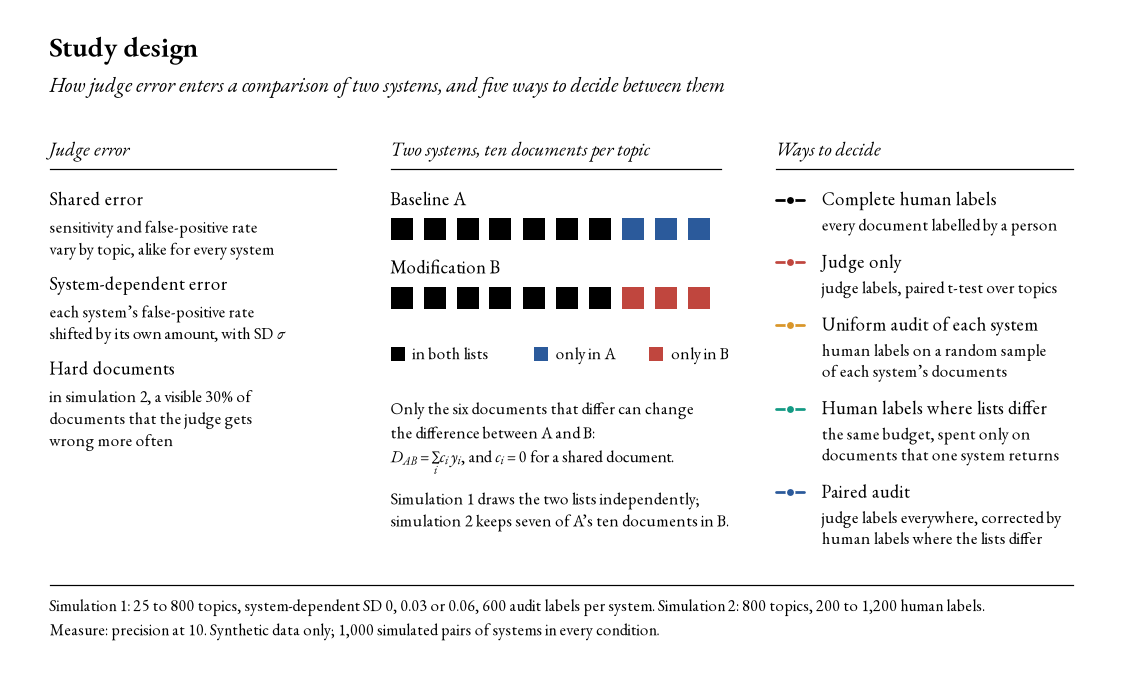

In [3]:
# Figure 1: study design
HAIR = "#000000"
W, H = 10.0, 5.95
fig = plt.figure(figsize=(W, H))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W)
ax.set_ylim(H, 0)          # positions in inches from the top
ax.axis("off")


def text(x, y, s, size=12, color=INK, **kw):
    return ax.text(x, y, s, fontsize=size, color=color, ha=kw.pop("ha", "left"), va=kw.pop("va", "baseline"), **kw)


def lines(x, y, body, size=10.8, color=INK_3, step=0.2):
    """Draw each line on its own baseline so that neighbouring columns line up exactly."""
    for k, line in enumerate(body.split("\n")):
        text(x, y + k * step, line, size=size, color=color)


text(0.35, 0.42, "Study design", size=18.5, fontweight="semibold")
text(0.35, 0.74, "How judge error enters a comparison of two systems, and five ways to decide between them",
     size=13.5, color=INK_2, style="italic")
HEAD = 1.32
for x0, x1, name in [(0.35, 2.95, "Judge error"), (3.45, 6.45, "Two systems, ten documents per topic"),
                     (6.95, 9.65, "Ways to decide")]:
    text(x0, HEAD, name, size=12.5, color=INK_2, style="italic")
    ax.plot([x0, x1], [HEAD + 0.12, HEAD + 0.12], color=HAIR, lw=0.8)
TOP = HEAD + 0.45

y = TOP
for name, note in [("Shared error", "sensitivity and false-positive rate\nvary by topic, alike for every system"),
                   ("System-dependent error", "each system’s false-positive rate\nshifted by its own amount, with SD $\\sigma$"),
                   ("Hard documents", "in simulation 2, a visible 30% of\ndocuments that the judge gets\nwrong more often")]:
    text(0.35, y, name)
    lines(0.35, y + 0.25, note)
    y += 0.25 + 0.2 * (note.count("\n") + 1) + 0.12

s = 0.2
for row, (label, colour) in enumerate([("Baseline A", NAVY), ("Modification B", CRIMSON)]):
    yy = TOP + row * 0.62
    text(3.45, yy, label)
    for k in range(10):
        ax.add_patch(Rectangle((3.45 + k * 0.3, yy + 0.12), s, s, facecolor=INK if k < 7 else colour, edgecolor="none"))
KEY_Y = TOP + 1.4
for kx, label, colour in [(3.45, "in both lists", INK), (4.75, "only in A", NAVY), (5.8, "only in B", CRIMSON)]:
    ax.add_patch(Rectangle((kx, KEY_Y - 0.115), 0.13, 0.13, facecolor=colour, edgecolor="none"))
    text(kx + 0.2, KEY_Y, label, size=10.8, color=INK_3)
lines(3.45, KEY_Y + 0.5, "Only the six documents that differ can change\nthe difference between A and B:\n"
      "$D_{AB} = \\sum_i c_i\\, y_i$, and $c_i = 0$ for a shared document.", step=0.22)
lines(3.45, KEY_Y + 1.32, "Simulation 1 draws the two lists independently;\nsimulation 2 keeps seven of A’s ten documents in B.",
      step=0.2)

PROCEDURES = [("Complete human labels", "every document labelled by a person", INK, "-"),
              ("Judge only", "judge labels, paired t-test over topics", CRIMSON, "-"),
              ("Uniform audit of each system", "human labels on a random sample\nof each system’s documents", OCHRE, "-"),
              ("Human labels where lists differ", "the same budget, spent only on\ndocuments that one system returns", TEAL, "-"),
              ("Paired audit", "judge labels everywhere, corrected by\nhuman labels where the lists differ", NAVY, "-")]
y = TOP
for name, note, colour, ls in PROCEDURES:
    ax.plot([6.95, 7.21], [y - 0.05, y - 0.05], color=colour, lw=1.8, ls=ls, solid_capstyle="round")
    ax.plot(7.08, y - 0.05, "o", color=colour, markersize=5.5, markeredgecolor=PAPER, markeredgewidth=1.0)
    text(7.37, y, name)
    lines(7.37, y + 0.23, note, step=0.19)
    y += 0.23 + 0.19 * (note.count("\n") + 1) + 0.15

ax.plot([0.35, 9.65], [5.22, 5.22], color=HAIR, lw=0.8)
text(0.35, 5.46, "Simulation 1: 25 to 800 topics, system-dependent SD 0, 0.03 or 0.06, 600 audit labels per system. "
     "Simulation 2: 800 topics, 200 to 1,200 human labels.", size=10.5, color=INK_3)
text(0.35, 5.68, "Measure: precision at 10. Synthetic data only; 1,000 simulated pairs of systems in every condition.",
     size=10.5, color=INK_3)
save(fig, "01_study_design.png")

## 3. Simulation 1: what system-dependent error does to a paired test

Each simulated pair of systems has a true mean precision drawn between 0.30 and 0.60, topic effects with standard deviation 0.15, and a judge with sensitivity 0.85 and false-positive rate 0.15 on average, both varying by topic with standard deviation 0.05. Four procedures decide whether A and B differ:

- a paired t-test on complete human labels;
- a paired t-test on judge labels;
- the judge-based difference corrected with a uniform random audit of 600 human labels per system;
- the same 1,200 human labels used alone, in a Welch test.

Kendall's $\tau$ between the judge-based and the human-based leaderboard is computed for 40 systems whose true precision runs from 0.15 to 0.75, averaged over 200 leaderboards.

In [4]:
# Simulation 1: judge labels, paired tests and leaderboard correlation
TOPICS = [25, 50, 100, 200, 400, 800]
SIGMAS = [0.0, 0.03, 0.06]   # SD of the system-dependent shift in the judge's false-positive rate
N_LEADER = 40                # systems on the simulated leaderboard
LEADER_RANGE = (0.15, 0.75)  # true mean precision across the leaderboard
REPS_TAU = 200               # simulated leaderboards per condition
AUDIT = 600                  # human-audited documents per system
SE_BASE, FPR_BASE = 0.85, 0.15


def true_labels(rng, theta, n_topics, topic_effect):
    """Binary relevance of the K documents a system returns for each topic."""
    p = np.clip(theta + topic_effect, 0.02, 0.98)
    return rng.random((n_topics, K)) < p[:, None]


def judge_labels(rng, y, se_t, fpr_t, delta_s):
    """Sensitivity se_t on relevant documents; false-positive rate fpr_t + delta_s on the others."""
    fpr = np.clip(fpr_t + delta_s, 0.0, 1.0)
    u = rng.random(y.shape)
    return np.where(y, u < se_t[:, None], u < fpr[:, None])


def shared_error(rng, n_topics):
    se_t = np.clip(SE_BASE + rng.normal(0, 0.05, n_topics), 0, 1)
    fpr_t = np.clip(FPR_BASE + rng.normal(0, 0.05, n_topics), 0, 1)
    return se_t, fpr_t


def paired_t(a, b):
    """Paired t-test on per-topic precision. Returns (significant, sign of the mean difference)."""
    d = a.mean(axis=1) - b.mean(axis=1)
    _, p = stats.ttest_1samp(d, 0.0)
    return p < ALPHA, np.sign(d.mean())


def audit_each_system(rng, ya, ja, yb, jb, n_audit):
    """Judge-based paired difference, with each system's judge error estimated from a uniform human audit."""
    d_judge = ja.mean(axis=1) - jb.mean(axis=1)
    est = d_judge.mean()
    var = d_judge.var(ddof=1) / d_judge.size
    for sign, y, j in ((1.0, ya, ja), (-1.0, yb, jb)):
        yf, jf = y.ravel().astype(float), j.ravel().astype(float)
        idx = rng.choice(yf.size, size=min(n_audit, yf.size), replace=False)
        rect = jf[idx] - yf[idx]
        est -= sign * rect.mean()
        var += rect.var(ddof=1) / rect.size
    z = est / np.sqrt(var)
    return 2 * (1 - stats.norm.cdf(abs(z))) < ALPHA, np.sign(est)


def human_only(rng, ya, yb, n_audit):
    """The same audit budget spent on human labels alone, without the judge."""
    a = ya.ravel()[rng.choice(ya.size, size=min(n_audit, ya.size), replace=False)].astype(float)
    b = yb.ravel()[rng.choice(yb.size, size=min(n_audit, yb.size), replace=False)].astype(float)
    _, p = stats.ttest_ind(a, b, equal_var=False)
    return p < ALPHA, np.sign(a.mean() - b.mean())


def compare(rng, true_gap, sigma, n_topics, n_rep=N_PAIRS):
    """Share of pairs in which each procedure declares a significant difference, by the sign of the claim."""
    keys = ("human_full", "judge_only", "audit_each_system", "human_only")
    pos, neg = dict.fromkeys(keys, 0), dict.fromkeys(keys, 0)
    for _ in range(n_rep):
        theta = rng.uniform(0.30, 0.60 - true_gap)
        topic = rng.normal(0, 0.15, n_topics)
        se_t, fpr_t = shared_error(rng, n_topics)
        da, db = rng.normal(0, sigma, 2) if sigma > 0 else (0.0, 0.0)
        ya, yb = true_labels(rng, theta + true_gap, n_topics, topic), true_labels(rng, theta, n_topics, topic)
        ja, jb = judge_labels(rng, ya, se_t, fpr_t, da), judge_labels(rng, yb, se_t, fpr_t, db)
        for key, (rej, sgn) in (("human_full", paired_t(ya, yb)), ("judge_only", paired_t(ja, jb)),
                                ("audit_each_system", audit_each_system(rng, ya, ja, yb, jb, AUDIT)),
                                ("human_only", human_only(rng, ya, yb, AUDIT))):
            pos[key] += bool(rej and sgn > 0)
            neg[key] += bool(rej and sgn < 0)
    return {k: {"right": pos[k] / n_rep, "wrong": neg[k] / n_rep} for k in keys}


def kendall_tau(rng, sigma, n_topics):
    """Mean Kendall's tau between judge-based and human-based leaderboards of N_LEADER systems."""
    taus = []
    for _ in range(REPS_TAU):
        thetas = np.linspace(*LEADER_RANGE, N_LEADER)
        topic = rng.normal(0, 0.15, n_topics)
        se_t, fpr_t = shared_error(rng, n_topics)
        deltas = rng.normal(0, sigma, N_LEADER) if sigma > 0 else np.zeros(N_LEADER)
        h, j = [], []
        for th, de in zip(thetas, deltas):
            y = true_labels(rng, th, n_topics, topic)
            h.append(y.mean())
            j.append(judge_labels(rng, y, se_t, fpr_t, de).mean())
        taus.append(stats.kendalltau(h, j)[0])
    return float(np.mean(taus))


start = time.time()
rng_1 = np.random.default_rng(SEED_1)
rows = []
for sigma in SIGMAS:
    for n_topics in TOPICS:
        r = compare(rng_1, 0.0, sigma, n_topics)
        tau = kendall_tau(rng_1, sigma, n_topics)
        rows.append({"sigma": sigma, "topics": n_topics, "tau": tau,
                     **{k: v["right"] + v["wrong"] for k, v in r.items()}})
equal_1 = pd.DataFrame(rows)
gap_rows = []
for sigma in SIGMAS:
    r = compare(rng_1, 0.03, sigma, 800)
    gap_rows += [{"sigma": sigma, "procedure": k, "right": v["right"], "wrong": v["wrong"]} for k, v in r.items()]
gap_1 = pd.DataFrame(gap_rows)
print(f"Simulation 1: {len(equal_1)} conditions with equal systems and {len(SIGMAS)} with a true gap of 0.03, "
      f"{time.time() - start:.0f} s")

Simulation 1: 18 conditions with equal systems and 3 with a true gap of 0.03, 28 s


### 3.1 More topics, more false positives

The table gives the share of equally effective pairs that each procedure declares different, so every entry should be near 0.05.

,"false positives, SD 0","false positives, SD 0.03","false positives, SD 0.06","tau, SD 0","tau, SD 0.03","tau, SD 0.06"
topics,,,,,,
25,0.042,0.088,0.156,0.905,0.879,0.825
50,0.055,0.130,0.272,0.933,0.899,0.839
100,0.051,0.165,0.397,0.956,0.916,0.845
200,0.063,0.282,0.539,0.971,0.923,0.856
400,0.061,0.411,0.663,0.983,0.929,0.858
800,0.041,0.505,0.757,0.992,0.934,0.855


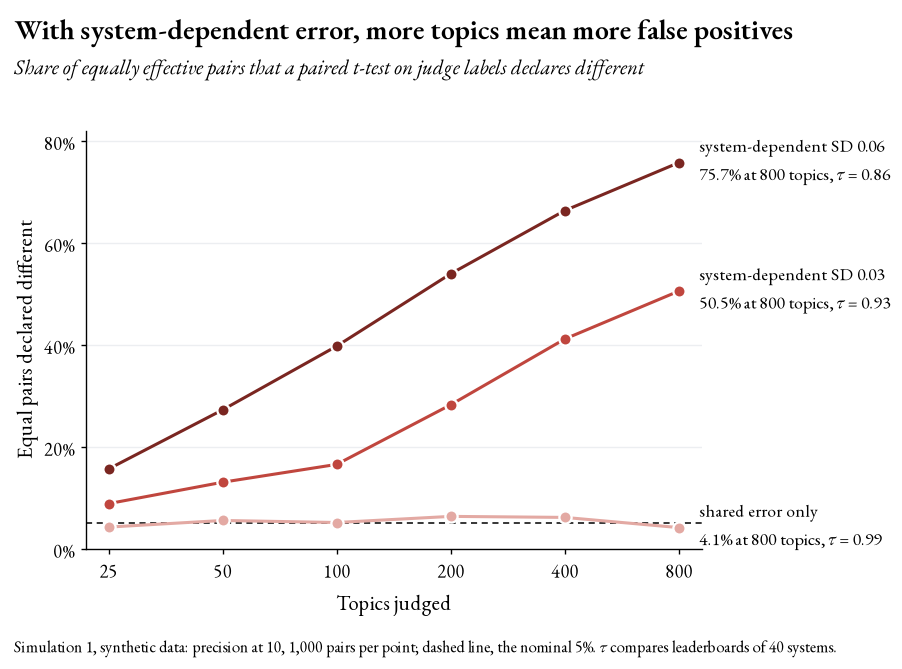

In [5]:
# Figure 2: false positives of a paired t-test on judge labels, by number of topics
columns = {f"false positives, SD {sd:g}": equal_1[equal_1.sigma == sd].set_index("topics").judge_only for sd in SIGMAS}
columns.update({f"tau, SD {sd:g}": equal_1[equal_1.sigma == sd].set_index("topics").tau for sd in SIGMAS})
display(pd.DataFrame(columns).round(3))

fig, ax = new_figure(6.2)
x = np.log2(TOPICS)
ax.axhline(0.05, color=INK_3, lw=1.0, ls=(0, (4, 3)), zorder=1)
names = {0.0: "shared error only", 0.03: "system-dependent SD 0.03", 0.06: "system-dependent SD 0.06"}
for sigma in SIGMAS:
    d = equal_1[equal_1.sigma == sigma]
    ax.plot(x, d.judge_only, color=ERROR_RAMP[sigma], lw=2.0, marker="o", markersize=8, markeredgecolor=PAPER,
            markeredgewidth=1.5, zorder=3, clip_on=False)
    tau_800 = d[d.topics == 800].tau.iloc[0]
    ax.text(x[-1] + 0.18, d.judge_only.iloc[-1], f"{names[sigma]}\n{d.judge_only.iloc[-1]:.1%} at 800 topics, $\\tau$ = {tau_800:.2f}",
            fontsize=11.5, color=INK_2, va="center", linespacing=1.25)
ax.set_xticks(x, [f"{t:,}" for t in TOPICS])
ax.set_xlim(x[0] - 0.2, x[-1] + 0.2)
ax.set_ylim(0, 0.82)
percent_axis(ax, step=20, top=80)
ax.grid(True, axis="y")
ax.set_xlabel("Topics judged")
ax.set_ylabel("Equal pairs declared different")
frame(fig, ax, "With system-dependent error, more topics mean more false positives",
      "Share of equally effective pairs that a paired t-test on judge labels declares different",
      "Simulation 1, synthetic data: precision at 10, 1,000 pairs per point; dashed line, the nominal 5%. "
      "$\\tau$ compares leaderboards of 40 systems.",
      right=0.66)
save(fig, "02_false_positives_grow_with_topics.png")

### 3.2 The leaderboard looks better as the decisions get worse

More topics make each system's score more precise, so the judge-based leaderboard agrees more closely with the human one. With system-dependent error, the same topics make the paired test more confident about a shift that is not there.

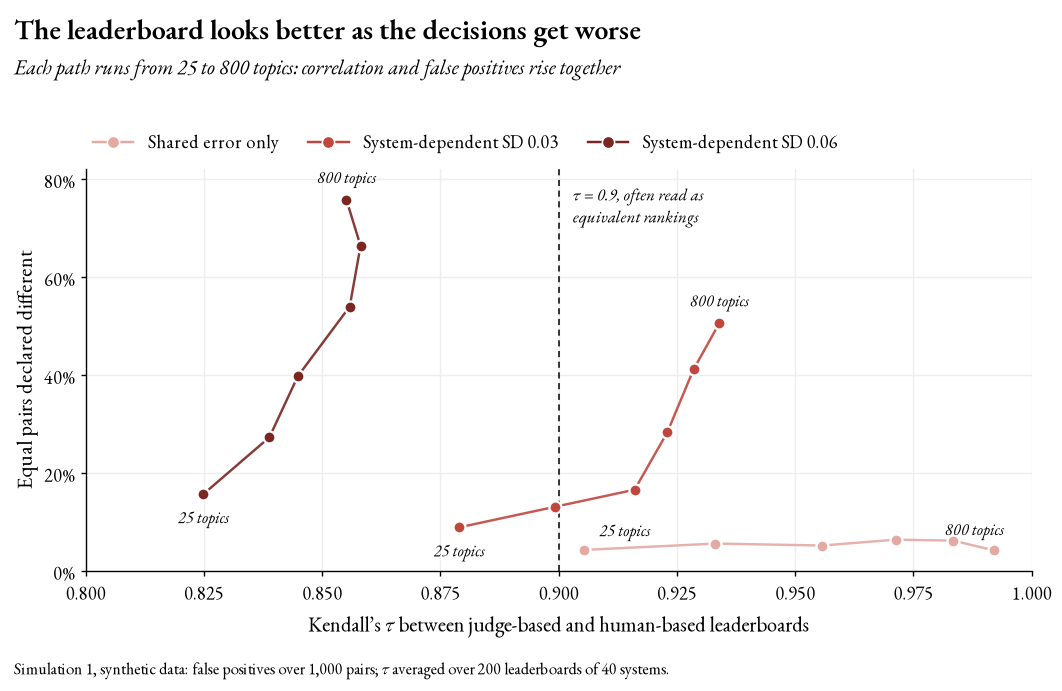

In [6]:
# Figure 3: Kendall's tau and false positives rise together
fig, ax = new_figure(6.4)
# where the first and last points of each path are labelled: offset in points and alignment
ENDS = {0.0: {25: ((10, 9), "left"), 800: ((6, 10), "right")},
        0.03: {25: ((0, -19), "center"), 800: ((0, 11), "center")},
        0.06: {25: ((0, -19), "center"), 800: ((0, 11), "center")}}
for sigma in SIGMAS:
    d = equal_1[equal_1.sigma == sigma]
    ax.plot(d.tau, d.judge_only, color=ERROR_RAMP[sigma], lw=1.6, alpha=0.9, zorder=2)
    ax.scatter(d.tau, d.judge_only, s=62, color=ERROR_RAMP[sigma], edgecolor=PAPER, linewidth=1.5, zorder=3)
    for t, xx, yy in zip(d.topics, d.tau, d.judge_only):
        if t in ENDS[sigma]:
            offset, ha = ENDS[sigma][t]
            ax.annotate(f"{t} topics", (xx, yy), xytext=offset, textcoords="offset points",
                        ha=ha, fontsize=10.5, color=INK_2, style="italic")
ax.axvline(0.9, color=INK_3, lw=1.0, ls=(0, (4, 3)), zorder=1)
ax.text(0.903, 0.79, "$\\tau$ = 0.9, often read as\nequivalent rankings", fontsize=11, color=INK_2, style="italic", va="top")
ax.set_xlim(0.8, 1.0)
ax.set_ylim(0, 0.82)
percent_axis(ax, step=20, top=80)
ax.grid(True)
ax.set_xlabel("Kendall’s $\\tau$ between judge-based and human-based leaderboards")
ax.set_ylabel("Equal pairs declared different")
LEGEND = {0.0: "Shared error only", 0.03: "System-dependent SD 0.03", 0.06: "System-dependent SD 0.06"}
ax.legend(handles=[series_handle(ERROR_RAMP[s], LEGEND[s], lw=1.6) for s in SIGMAS],
          loc="lower left", bbox_to_anchor=(0.0, 1.02), ncol=3, handlelength=2.2, columnspacing=1.6, borderaxespad=0.0)
frame(fig, ax, "The leaderboard looks better as the decisions get worse",
      "Each path runs from 25 to 800 topics: correlation and false positives rise together",
      "Simulation 1, synthetic data: false positives over 1,000 pairs; $\\tau$ averaged over 200 leaderboards of 40 systems.",
      top_pad=1.6)
save(fig, "03_tau_rises_with_false_positives.png")

### 3.3 With a real improvement, the judge can back the wrong system

Here B is better than A by 0.03 in precision at 10, and 800 topics are judged. A correct claim says that B is better; a wrong claim says that A is.

,real improvement found,no significant difference,wrong system declared better
Complete human labels,0.979,0.021,0.000
"Judge, shared error only",0.776,0.224,0.000
"Judge, system-dependent SD 0.03",0.607,0.317,0.076
"Judge, system-dependent SD 0.06",0.576,0.207,0.217


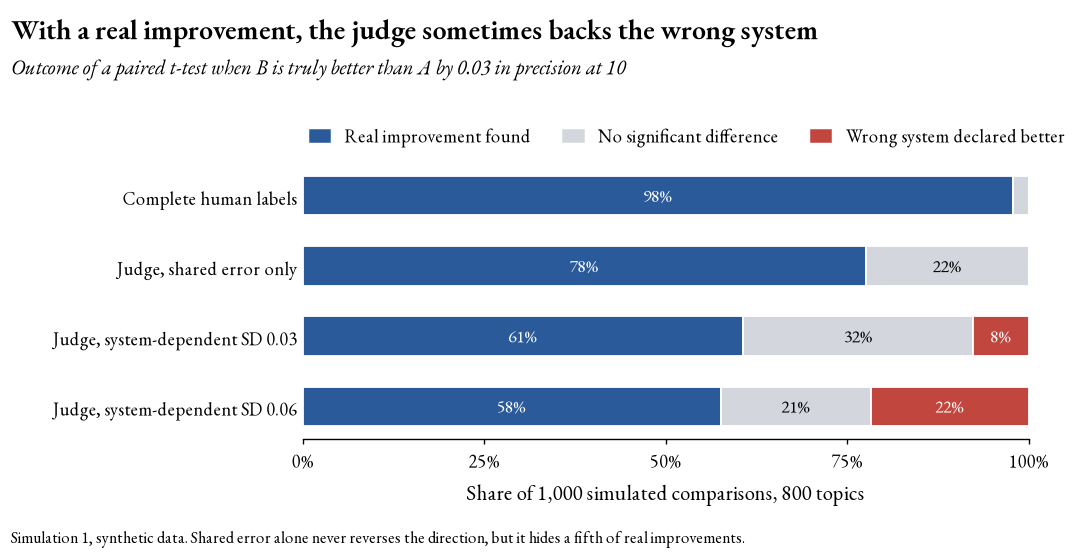

In [7]:
# Figure 4: outcome of a paired t-test on judge labels when one system is truly better
rows = [("Complete human labels", gap_1[(gap_1.procedure == "human_full") & (gap_1.sigma == 0.03)].iloc[0])]
for sigma in SIGMAS:
    rows.append((f"Judge, {names[sigma]}", gap_1[(gap_1.procedure == "judge_only") & (gap_1.sigma == sigma)].iloc[0]))
table = pd.DataFrame({label: {"real improvement found": r.right, "no significant difference": 1 - r.right - r.wrong,
                              "wrong system declared better": r.wrong} for label, r in rows}).T
display(table.round(3))

fig, ax = new_figure(5.2)
y = np.arange(len(table))[::-1]
left = np.zeros(len(table))
for col, colour, ink in [("real improvement found", NAVY, PAPER), ("no significant difference", NEUTRAL, INK),
                         ("wrong system declared better", CRIMSON, PAPER)]:
    v = table[col].to_numpy()
    ax.barh(y, v, left=left, height=0.56, color=colour, edgecolor=PAPER, linewidth=1.2)
    for yy, ll, vv in zip(y, left, v):
        if vv >= 0.05:
            ax.text(ll + vv / 2, yy, f"{vv:.0%}", ha="center", va="center", fontsize=11.5, color=ink)
    left += v
ax.set_yticks(y, table.index)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 1)
percent_axis(ax, axis="x", step=25, top=100)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Share of 1,000 simulated comparisons, 800 topics")
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=c, label=l) for l, c in
                   [("Real improvement found", NAVY), ("No significant difference", NEUTRAL),
                    ("Wrong system declared better", CRIMSON)]],
          loc="lower left", bbox_to_anchor=(0.0, 1.03), ncol=3, handlelength=1.1, columnspacing=1.8, borderaxespad=0.0)
frame(fig, ax, "With a real improvement, the judge sometimes backs the wrong system",
      "Outcome of a paired t-test when B is truly better than A by 0.03 in precision at 10",
      "Simulation 1, synthetic data. Shared error alone never reverses the direction, but it hides a fifth of real improvements.",
      left=0.3, top_pad=1.55)
save(fig, "04_wrong_winners.png")

### 3.4 A uniform audit removes the error, and most of the power with it

The obvious correction is to audit each system: label a random sample of its documents by hand, estimate how far its judge-based score is off, and subtract. With 600 human labels per system, this restores the false-positive rate, but it finds a real improvement of 0.03 in only about a quarter of comparisons. The audit spends most of its labels on documents that both systems share.

,false positives,real improvement found
Complete human labels,0.046,0.979
Judge only,0.505,0.607
"Judge, with a uniform audit of each system (1,200 labels)",0.051,0.229
"The same 1,200 human labels alone",0.049,0.185


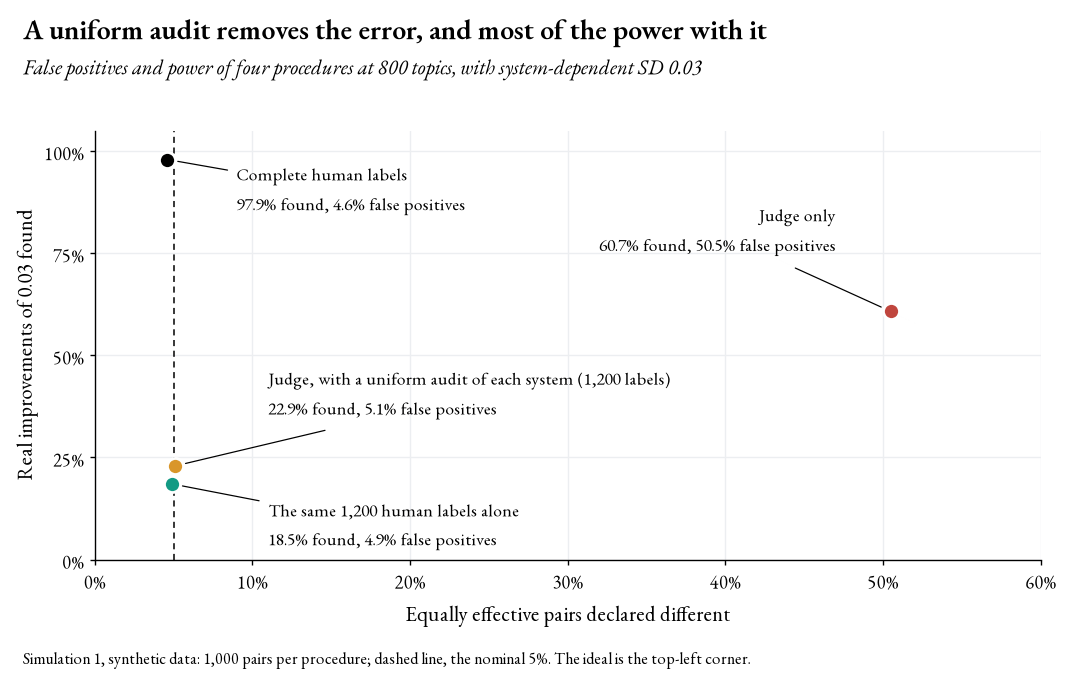

In [8]:
# Figure 5: false positives against power at 800 topics, system-dependent SD 0.03
order = [("human_full", "Complete human labels", INK), ("judge_only", "Judge only", CRIMSON),
         ("audit_each_system", "Judge, with a uniform audit of each system (1,200 labels)", OCHRE),
         ("human_only", "The same 1,200 human labels alone", TEAL)]
fp = equal_1[(equal_1.sigma == 0.03) & (equal_1.topics == 800)].iloc[0]
pw = gap_1[gap_1.sigma == 0.03].set_index("procedure")
trade = pd.DataFrame({label: {"false positives": fp[key], "real improvement found": pw.loc[key, "right"]}
                      for key, label, _ in order}).T
display(trade.round(3))

fig, ax = new_figure(6.3)
ax.axvline(0.05, color=INK_3, lw=1.0, ls=(0, (4, 3)), zorder=1)
# label positions in data units, clear of the points and of each other
PLACE = {"human_full": (0.09, 0.90, "left"), "judge_only": (0.47, 0.80, "right"),
         "audit_each_system": (0.11, 0.40, "left"), "human_only": (0.11, 0.08, "left")}
for key, label, colour in order:
    xx, yy = fp[key], pw.loc[key, "right"]
    ax.scatter(xx, yy, s=110, color=colour, edgecolor=PAPER, linewidth=1.8, zorder=3)
    tx, ty, ha = PLACE[key]
    ax.annotate(f"{label}\n{yy:.1%} found, {xx:.1%} false positives", (xx, yy), xytext=(tx, ty), textcoords="data",
                ha=ha, va="center", fontsize=11.5, color=INK_2, linespacing=1.3,
                arrowprops=dict(arrowstyle="-", color=INK_3, lw=0.8, shrinkA=4, shrinkB=7))
ax.set_xlim(0, 0.6)
ax.set_ylim(0, 1.05)
percent_axis(ax, axis="x", step=10, top=60)
percent_axis(ax, axis="y", step=25, top=100)
ax.grid(True)
ax.set_xlabel("Equally effective pairs declared different")
ax.set_ylabel("Real improvements of 0.03 found")
frame(fig, ax, "A uniform audit removes the error, and most of the power with it",
      "False positives and power of four procedures at 800 topics, with system-dependent SD 0.03",
      "Simulation 1, synthetic data: 1,000 pairs per procedure; dashed line, the nominal 5%. The ideal is the top-left corner.")
save(fig, "05_uniform_audit_costs_power.png")

## 4. Simulation 2: paired audits when two systems share documents

A modified system usually keeps most of its baseline's results. Here B keeps 7 of A's 10 documents on every topic and replaces three, with a true improvement of 0.03 in precision at 10 concentrated in the replaced documents. The judge errs more often on a visible class of hard documents (30% of documents, false-positive rate 0.30 against 0.08) and over-rates the documents that only B retrieves by 0.10, an error that no uncertainty signal would flag.

Every procedure gets the same human budget, from 0.25 to 1.5 labels per topic (200 to 1,200 labels at 800 topics), and every procedure ends with a paired t-test over topics on its per-topic estimate of the difference, so that both topic sampling and audit sampling enter the variance. Inclusion probabilities $\pi_i$ are fixed in advance, so every corrected estimate is unbiased for the human-based difference.

- **Uniform audit of each system:** as in simulation 1, a random sample of each system's documents.
- **Human labels where the lists differ:** a uniform sample of the six differing documents, without the judge.
- **Paired audit, uniform:** the difference estimator $\hat D_{AB} = \sum_i c_i \hat y_i + \sum_{i \in S} c_i (y_i - \hat y_i)/\pi_i$, which corrects the judge-based difference with human labels on a sample $S$ of the differing documents (Särndal et al., 1992).
- **Paired audit, targeted:** the same estimator with $\pi_i$ proportional to $|c_i|$ times the square root of the judge's predicted error probability, mixed half and half with uniform sampling because the error on B's documents is not visible to any predictor.

In [9]:
# Simulation 2: targeted paired audits when two systems share documents
SHARED = 7                        # B keeps 7 of A's 10 documents
NEW = K - SHARED                  # documents that only one of the two systems returns, per system and topic
TOPICS_2 = 800
BUDGETS = [0.25, 0.5, 1.0, 1.5]   # human labels per topic for every audit (1.5 is 1,200 at 800 topics)
SE = 0.85                         # judge sensitivity on easy relevant documents (0.75 on hard ones)
FPR_EASY, FPR_HARD = 0.08, 0.30   # judge false-positive rate on easy and hard non-relevant documents
P_HARD = 0.30                     # share of hard documents
DELTA = 0.10                      # extra false-positive rate on documents that only B retrieves
MIX = 0.5                         # share of the targeted audit spread uniformly over the differing documents
GAP = 0.03                        # true improvement of B over A in precision at 10
# predicted error probability from the visible feature alone, assuming a relevance rate of 0.45
Q_EASY = 0.45 * (1 - SE) + 0.55 * FPR_EASY
Q_HARD = 0.45 * (1 - SE + 0.10) + 0.55 * FPR_HARD


def one_pair(rng, gap):
    """Human and judge labels for one pair of systems: shared documents, A-only and B-only documents."""
    theta = rng.uniform(0.30, 0.55)
    p = np.clip(theta + rng.normal(0, 0.15, TOPICS_2), 0.02, 0.98)[:, None]
    pb = np.clip(p + gap * K / NEW, 0.0, 1.0)
    y_sh = rng.random((TOPICS_2, SHARED)) < p
    y_a = rng.random((TOPICS_2, NEW)) < p
    y_b = rng.random((TOPICS_2, NEW)) < pb
    h_sh, h_a, h_b = (rng.random(s) < P_HARD for s in ((TOPICS_2, SHARED), (TOPICS_2, NEW), (TOPICS_2, NEW)))
    se_t = np.clip(SE + rng.normal(0, 0.05, TOPICS_2), 0, 1)[:, None]          # shared error, by topic
    f_t = rng.normal(0, 0.05, TOPICS_2)[:, None]

    def judge(y, h, extra):
        fpr = np.clip(np.where(h, FPR_HARD, FPR_EASY) + f_t + extra, 0, 1)
        se = np.clip(se_t - 0.10 * h, 0, 1)
        u = rng.random(y.shape)
        return np.where(y, u < se, u < fpr)

    j_sh = judge(y_sh, h_sh, 0.0)              # a shared document gets the same judge label in both lists
    j_a, j_b = judge(y_a, h_a, 0.0), judge(y_b, h_b, DELTA)
    return y_sh, y_a, y_b, j_sh, j_a, j_b, h_a, h_b


def t_test(z):
    """Paired t-test over topics on per-topic estimates of the difference B minus A."""
    _, p = stats.ttest_1samp(z, 0.0)
    return p < ALPHA, np.sign(z.mean())


def poisson(rng, pi):
    return rng.random(pi.shape) < pi


def procedures(rng, gap, budget):
    y_sh, y_a, y_b, j_sh, j_a, j_b, h_a, h_b = one_pair(rng, gap)
    f = lambda x: x.astype(float)
    d_human = (f(y_b).sum(1) - f(y_a).sum(1)) / K
    d_judge = (f(j_b).sum(1) - f(j_a).sum(1)) / K
    out = {"human_full": t_test(d_human), "judge_only": t_test(d_judge)}

    # uniform audit of each system: its ten documents per topic, sampled with probability (budget / 2) / K
    pi_sys = (budget / 2) / K
    err = lambda y, j: f(y) - f(j)              # human minus judge label
    ra = np.concatenate([err(y_sh, j_sh), err(y_a, j_a)], axis=1) * poisson(rng, np.full((TOPICS_2, K), pi_sys)) / pi_sys
    rb = np.concatenate([err(y_sh, j_sh), err(y_b, j_b)], axis=1) * poisson(rng, np.full((TOPICS_2, K), pi_sys)) / pi_sys
    out["audit_each_system"] = t_test(d_judge + (rb.sum(1) - ra.sum(1)) / K)

    # differing documents only: weights c = +1/K for B-only and -1/K for A-only documents
    pi_u = np.full((TOPICS_2, 2 * NEW), budget / (2 * NEW))
    y_d = np.concatenate([f(y_b), f(y_a)], axis=1)
    j_d = np.concatenate([f(j_b), f(j_a)], axis=1)
    c = np.concatenate([np.full(NEW, 1.0 / K), np.full(NEW, -1.0 / K)])
    s = poisson(rng, pi_u)
    out["human_where_lists_differ"] = t_test((c * y_d * s / pi_u).sum(1))
    out["paired_uniform"] = t_test(d_judge + (c * (y_d - j_d) * s / pi_u).sum(1))

    # targeted: probabilities proportional to |c| times the square root of the predicted error probability
    q = np.where(np.concatenate([h_b, h_a], axis=1), Q_HARD, Q_EASY)
    w = np.sqrt(q) / np.sqrt(q).sum(1, keepdims=True)
    pi_t = np.clip(budget * (MIX / (2 * NEW) + (1 - MIX) * w), 0, 1)
    s_t = poisson(rng, pi_t)
    out["paired_targeted"] = t_test(d_judge + (c * (y_d - j_d) * s_t / pi_t).sum(1))
    return out


def rates(rng, gap, budget, n_rep=N_PAIRS):
    keys = ("human_full", "judge_only", "audit_each_system", "human_where_lists_differ", "paired_uniform", "paired_targeted")
    right, wrong = dict.fromkeys(keys, 0), dict.fromkeys(keys, 0)
    for _ in range(n_rep):
        for k, (rej, sgn) in procedures(rng, gap, budget).items():
            right[k] += bool(rej and sgn > 0)
            wrong[k] += bool(rej and sgn < 0)
    return {k: (right[k] / n_rep, wrong[k] / n_rep) for k in keys}


start = time.time()
rng_2 = np.random.default_rng(SEED_2)
rows = []
for b in BUDGETS:
    for condition, gap in (("equal systems", 0.0), ("true gap 0.03", GAP)):
        for k, (right, wrong) in rates(rng_2, gap, b).items():
            rows.append({"labels": round(b * TOPICS_2), "condition": condition, "procedure": k, "right": right, "wrong": wrong})
sim_2 = pd.DataFrame(rows)
print(f"Simulation 2: {len(BUDGETS)} budgets x 2 conditions x {N_PAIRS:,} pairs, {time.time() - start:.0f} s")

Simulation 2: 4 budgets x 2 conditions x 1,000 pairs, 15 s


### 4.1 Human labels where the lists differ, combined with the judge's

Power is the share of the 1,000 pairs with a true improvement in which the procedure declares B significantly better.

procedure,Complete human labels,Judge only,Uniform audit of each system,Human labels where the lists differ,"Paired audit, uniform","Paired audit, targeted"
labels,,,,,,
200,1.0,1.0,0.068,0.175,0.350,0.402
400,1.0,1.0,0.102,0.318,0.651,0.625
800,1.0,1.0,0.182,0.582,0.895,0.911
1200,1.0,1.0,0.254,0.782,0.979,0.981


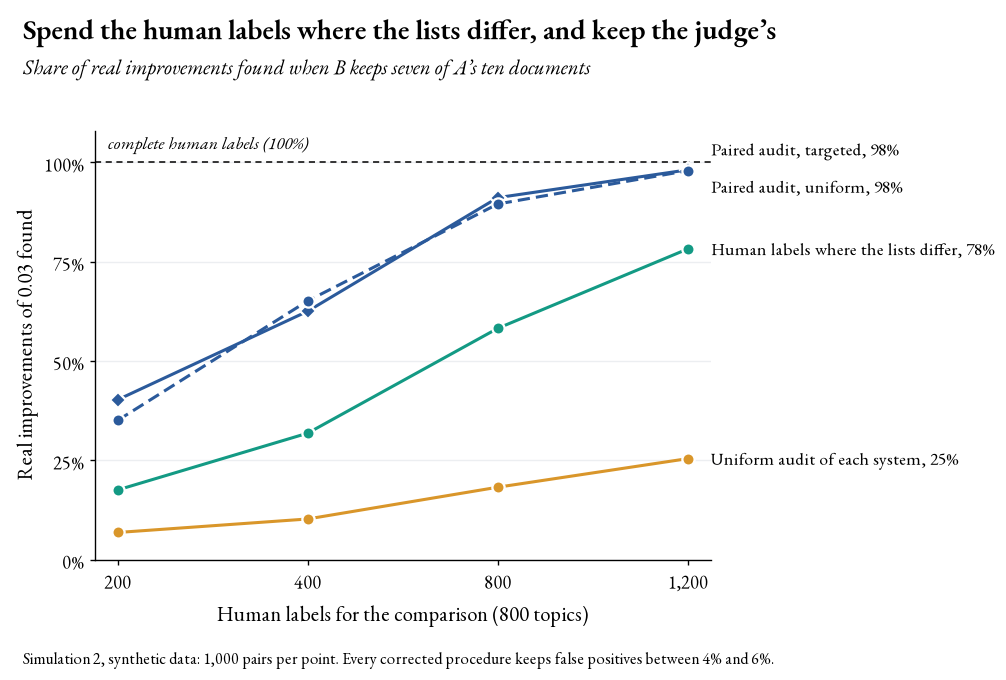

procedure,Complete human labels,Judge only,Uniform audit of each system,Human labels where the lists differ,"Paired audit, uniform","Paired audit, targeted"
labels,,,,,,
200,0.046,0.966,0.041,0.052,0.051,0.051
400,0.056,0.972,0.044,0.049,0.045,0.047
800,0.044,0.964,0.046,0.046,0.052,0.054
1200,0.047,0.971,0.058,0.054,0.049,0.047


In [10]:
# Figure 6: real improvements found, by number of human labels
LABELS_2 = {"human_full": "Complete human labels", "judge_only": "Judge only",
            "audit_each_system": "Uniform audit of each system", "human_where_lists_differ": "Human labels where the lists differ",
            "paired_uniform": "Paired audit, uniform", "paired_targeted": "Paired audit, targeted"}
power = sim_2[sim_2.condition == "true gap 0.03"].pivot(index="labels", columns="procedure", values="right")
display(power[list(LABELS_2)].rename(columns=LABELS_2).round(3))

SERIES = [("paired_targeted", "Paired audit, targeted", NAVY, "-", "D"),
          ("paired_uniform", "Paired audit, uniform", NAVY, (0, (4, 2)), "o"),
          ("human_where_lists_differ", "Human labels where the lists differ", TEAL, "-", "o"),
          ("audit_each_system", "Uniform audit of each system", OCHRE, "-", "o")]
fig, ax = new_figure(6.3)
xb = np.arange(len(BUDGETS))
ax.axhline(power["human_full"].iloc[0], color=INK_3, lw=1.0, ls=(0, (4, 3)), zorder=1)
ax.text(xb[0] - 0.05, power["human_full"].iloc[0] + 0.02, f"complete human labels ({power['human_full'].iloc[0]:.0%})",
        fontsize=11.5, color=INK_2, style="italic", va="bottom")
label_y = {"paired_targeted": 0.052, "paired_uniform": -0.04, "human_where_lists_differ": 0.0, "audit_each_system": 0.0}
for key, label, colour, ls, marker in SERIES:
    ax.plot(xb, power[key], color=colour, lw=2.0, ls=ls, marker=marker, markersize=8 if marker == "o" else 7,
            markeredgecolor=PAPER, markeredgewidth=1.5, zorder=3, clip_on=False)
    ax.text(xb[-1] + 0.12, power[key].iloc[-1] + label_y[key], f"{label}, {power[key].iloc[-1]:.0%}",
            fontsize=11.5, color=INK_2, va="center")
ax.set_xticks(xb, [f"{v:,}" for v in power.index])
ax.set_xlim(xb[0] - 0.12, xb[-1] + 0.12)
ax.set_ylim(0, 1.08)
percent_axis(ax, step=25, top=100)
ax.grid(True, axis="y")
ax.set_xlabel("Human labels for the comparison (800 topics)")
ax.set_ylabel("Real improvements of 0.03 found")
frame(fig, ax, "Spend the human labels where the lists differ, and keep the judge’s",
      "Share of real improvements found when B keeps seven of A’s ten documents",
      "Simulation 2, synthetic data: 1,000 pairs per point. Every corrected procedure keeps false positives between 4% and 6%.",
      right=0.66)
save(fig, "06_labels_where_the_lists_differ.png")

# False positives of every procedure with equal systems (both directions)
fp_2 = sim_2[sim_2.condition == "equal systems"].assign(rate=lambda d: d.right + d.wrong)
display(fp_2.pivot(index="labels", columns="procedure", values="rate")[list(LABELS_2)].rename(columns=LABELS_2).round(3))

### 4.2 Where the gain comes from

Moving from a uniform audit of each system to the targeted paired audit changes three things at once. Taking them one at a time shows which of them matters. The last column of the table below measures how much the judge's labels could help in this world: the share of the variance of the human labels on the differing documents that the judge's labels explain. With uniform sampling, a control variate that explains a share $R^2$ of the variance can raise the effective number of human labels by at most $1/(1 - R^2)$.

procedure,Uniform audit of each system,Human labels where the lists differ,"Paired audit, uniform","Paired audit, targeted"
labels,,,,
400,0.102,0.318,0.651,0.625
1200,0.254,0.782,0.979,0.981


Judge labels explain 0.40 of the variance of the human labels on the differing documents; at most a 1.66-fold gain in effective labels under uniform sampling


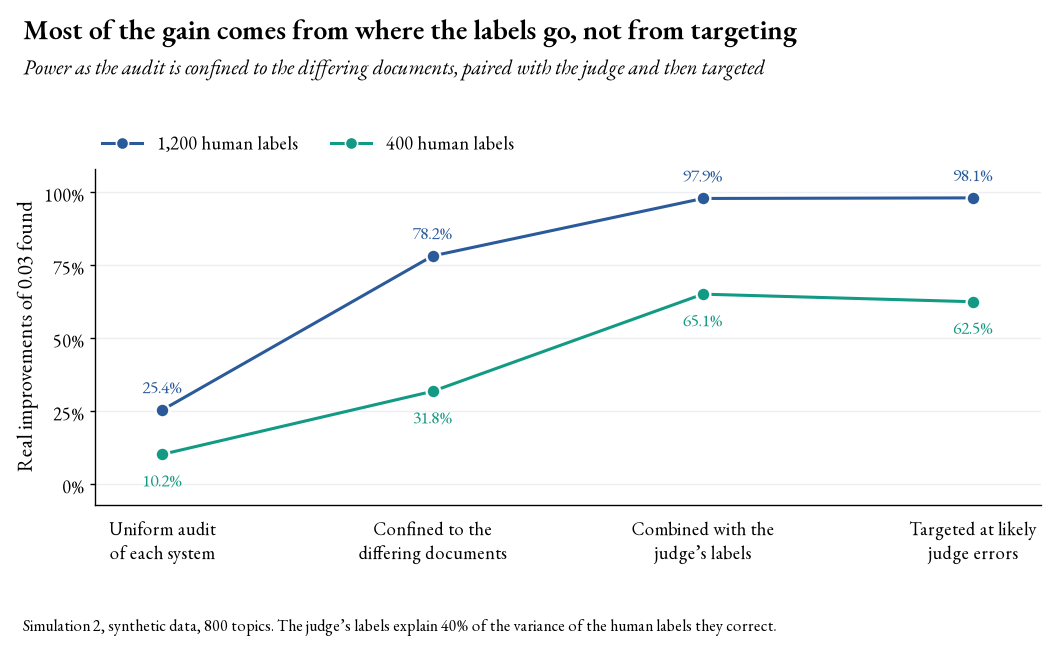

In [11]:
# Figure 7: the gain from confining, pairing and targeting the audit
STEPS = [("audit_each_system", "Uniform audit\nof each system"), ("human_where_lists_differ", "Confined to the\ndiffering documents"),
         ("paired_uniform", "Combined with the\njudge’s labels"), ("paired_targeted", "Targeted at likely\njudge errors")]
steps = power.loc[[400, 1200], [k for k, _ in STEPS]]
display(steps.rename(columns=LABELS_2).round(3))

# How much of the variance of the human labels on the differing documents do the judge's labels explain?
rng_r2 = np.random.default_rng(SEED_2 + 1)
y_all, j_all = [], []
for _ in range(50):
    y_sh, y_a, y_b, j_sh, j_a, j_b, h_a, h_b = one_pair(rng_r2, GAP)
    y_all.append(np.concatenate([y_a, y_b], axis=1).ravel())
    j_all.append(np.concatenate([j_a, j_b], axis=1).ravel())
r2 = np.corrcoef(np.concatenate(y_all), np.concatenate(j_all))[0, 1] ** 2
print(f"Judge labels explain {r2:.2f} of the variance of the human labels on the differing documents; "
      f"at most a {1 / (1 - r2):.2f}-fold gain in effective labels under uniform sampling")

fig, ax = new_figure(6.0)
xs = np.arange(len(STEPS))
for labels, colour in [(1200, NAVY), (400, TEAL)]:
    v = steps.loc[labels].to_numpy()
    ax.plot(xs, v, color=colour, lw=2.0, marker="o", markersize=9, markeredgecolor=PAPER, markeredgewidth=1.5,
            zorder=3, clip_on=False)
    for xx, vv in zip(xs, v):
        ax.annotate(f"{vv:.1%}", (xx, vv), xytext=(0, 11 if labels == 1200 else -21), textcoords="offset points",
                    ha="center", fontsize=11.5, color=colour)
ax.set_xticks(xs, [label for _, label in STEPS])
ax.tick_params(axis="x", length=0, pad=8)
ax.set_xlim(-0.25, len(STEPS) - 0.75)
ax.set_ylim(-0.07, 1.08)
percent_axis(ax, step=25, top=100)
ax.grid(True, axis="y")
ax.set_ylabel("Real improvements of 0.03 found")
ax.legend(handles=[series_handle(NAVY, "1,200 human labels"), series_handle(TEAL, "400 human labels")],
          loc="lower left", bbox_to_anchor=(0.0, 1.02), ncol=2, handlelength=2.2, columnspacing=1.8, borderaxespad=0.0)
frame(fig, ax, "Most of the gain comes from where the labels go, not from targeting",
      "Power as the audit is confined to the differing documents, paired with the judge and then targeted",
      f"Simulation 2, synthetic data, 800 topics. The judge’s labels explain {r2:.0%} of the variance of the human labels they correct.",
      top_pad=1.6, bottom_pad=1.35)
save(fig, "07_where_the_gain_comes_from.png")

## 5. Summary

In [12]:
# Numbers quoted in the README
e = equal_1.set_index(["sigma", "topics"])
g = gap_1.set_index(["sigma", "procedure"])
report = {
    "false positives, judge only, SD 0, 800 topics": e.loc[(0.0, 800), "judge_only"],
    "false positives, judge only, SD 0.03, 25 topics": e.loc[(0.03, 25), "judge_only"],
    "false positives, judge only, SD 0.03, 800 topics": e.loc[(0.03, 800), "judge_only"],
    "false positives, judge only, SD 0.06, 25 topics": e.loc[(0.06, 25), "judge_only"],
    "false positives, judge only, SD 0.06, 800 topics": e.loc[(0.06, 800), "judge_only"],
    "tau, SD 0, 800 topics": e.loc[(0.0, 800), "tau"],
    "tau, SD 0.03, 25 topics": e.loc[(0.03, 25), "tau"],
    "tau, SD 0.03, 800 topics": e.loc[(0.03, 800), "tau"],
    "tau, SD 0.06, 800 topics": e.loc[(0.06, 800), "tau"],
    "false positives, audit, SD 0.06, 800 topics": e.loc[(0.06, 800), "audit_each_system"],
    "power, complete human labels, SD 0.03": g.loc[(0.03, "human_full"), "right"],
    "power, judge only, SD 0": g.loc[(0.0, "judge_only"), "right"],
    "wrong winner, judge only, SD 0.03": g.loc[(0.03, "judge_only"), "wrong"],
    "wrong winner, judge only, SD 0.06": g.loc[(0.06, "judge_only"), "wrong"],
    "power, uniform audit, SD 0.03": g.loc[(0.03, "audit_each_system"), "right"],
    "power, human labels alone, SD 0.03": g.loc[(0.03, "human_only"), "right"],
    "sim 2, power, 1,200 labels, uniform audit": power.loc[1200, "audit_each_system"],
    "sim 2, power, 1,200 labels, where lists differ": power.loc[1200, "human_where_lists_differ"],
    "sim 2, power, 1,200 labels, paired uniform": power.loc[1200, "paired_uniform"],
    "sim 2, power, 1,200 labels, paired targeted": power.loc[1200, "paired_targeted"],
    "sim 2, power, 400 labels, paired uniform": power.loc[400, "paired_uniform"],
    "sim 2, power, 400 labels, paired targeted": power.loc[400, "paired_targeted"],
    "sim 2, false positives, corrected, lowest": fp_2[~fp_2.procedure.isin(["judge_only"])].rate.min(),
    "sim 2, false positives, corrected, highest": fp_2[~fp_2.procedure.isin(["judge_only"])].rate.max(),
    "sim 2, false positives, judge only, lowest": fp_2[fp_2.procedure == "judge_only"].rate.min(),
    "R2 of judge labels, differing documents": r2,
}
pd.Series({k: f"{float(v):.3f}" for k, v in report.items()}, name="value").to_frame()

,value
"false positives, judge only, SD 0, 800 topics",0.041
"false positives, judge only, SD 0.03, 25 topics",0.088
"false positives, judge only, SD 0.03, 800 topics",0.505
"false positives, judge only, SD 0.06, 25 topics",0.156
"false positives, judge only, SD 0.06, 800 topics",0.757
"tau, SD 0, 800 topics",0.992
"tau, SD 0.03, 25 topics",0.879
"tau, SD 0.03, 800 topics",0.934
"tau, SD 0.06, 800 topics",0.855
"false positives, audit, SD 0.06, 800 topics",0.047
